<a href="https://colab.research.google.com/github/suleimanhauwawwal/data-science-cohort/blob/main/FPL_Data_Science_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fantasy Premier League: Who Deserves More Points?

A full data science project, start to finish, on live data from the official Fantasy Premier League API.

**The question:** some players score fewer FPL points than their performances deserve. Bad luck, wasted chances, a keeper having a blinder. If we can spot them, we can buy them before their points catch up.

**The plan**

1. Ask the question
2. Get the data
3. Understand the data
4. Clean the data
5. Explore the data
6. Build a model
7. Evaluate the model
8. Use the model
9. Share the work

## 1. Ask the question

- **What** are we trying to find? Players whose points are lower than their underlying numbers say they should be.
- **Why** does it matter? In FPL you have a fixed budget. Buying a player just before his points go up is how you win your mini league.
- **How** will we answer it? Teach a model what points a player "should" have from how well he actually played (chances, minutes, defending), then compare that to the points he really got.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Get the data

The FPL website gets its data from a public API. We ask it for data and it sends back JSON, the same thing the website uses to show you player prices and points.

In [2]:
url = "https://fantasy.premierleague.com/api/bootstrap-static/"
data = requests.get(url).json()

data.keys()

dict_keys(['chips', 'contests', 'events', 'game_settings', 'game_config', 'phases', 'teams', 'total_players', 'element_stats', 'element_types', 'elements'])

Three parts are useful to us:

- `elements`: one row per player
- `teams`: the 20 Premier League clubs
- `element_types`: the four positions (GKP, DEF, MID, FWD)

In [3]:
players = pd.DataFrame(data["elements"])
teams = pd.DataFrame(data["teams"])
positions = pd.DataFrame(data["element_types"])

players.shape

(672, 109)

## 3. Understand the data

Hundreds of players and around 100 columns. Let's look before we touch anything.

In [4]:
players.head()

,can_transact,can_select,chance_of_playing_next_round,chance_of_playing_this_round,code,cost_change_event,cost_change_event_fall,cost_change_start,cost_change_start_fall,price_change_percent,price_change_hourly_rate,price_change_projections,price_change_locked_until,price_change_calibrating,dreamteam_count,...,expected_assists_per_90,expected_goal_involvements_per_90,expected_goals_conceded_per_90,goals_conceded_per_90,now_cost_rank,now_cost_rank_type,form_rank,form_rank_type,points_per_game_rank,points_per_game_rank_type,selected_rank,selected_rank_type,starts_per_90,clean_sheets_per_90,defensive_contribution_per_90
0,True,True,NaN,NaN,154561,1,-1,3,-3,0.2,100,"[{'offset': 0, 'projected_percent': '0.7', 'li...",None,False,2,...,0.00,0.00,0.76,0.50,47,1,24,4,14,1,6,1,1.00,0.70,0.00
1,True,True,NaN,NaN,109745,0,0,-1,1,-98.4,0,"[{'offset': 0, 'projected_percent': '-98.4', '...",None,False,0,...,0.00,0.00,0.00,0.00,322,14,554,71,604,72,458,55,0.00,0.00,0.00
2,True,True,NaN,NaN,437495,0,0,-1,1,-94.0,0,"[{'offset': 0, 'projected_percent': '-94.0', '...",None,False,0,...,0.00,0.00,0.00,0.00,341,17,561,73,607,73,549,65,0.00,0.00,0.00
3,True,True,NaN,NaN,226597,1,-1,1,-1,27.9,322,"[{'offset': 0, 'projected_percent': '29.6', 'l...",None,False,1,...,0.02,0.17,0.76,0.50,8,1,3,2,7,3,12,3,1.00,0.70,9.10
4,True,True,100.0,100.0,445122,0,0,0,0,51.5,22,"[{'offset': 0, 'projected_percent': '51.8', 'l...",None,False,0,...,0.15,0.16,1.09,0.81,42,2,97,40,245,90,166,66,0.81,0.54,4.84


Things to notice:

- `team` and `element_type` are **numbers**, not names. We need to translate them.
- `now_cost` is in tenths: 105 means £10.5m.
- Columns like `expected_goals` look like numbers but are stored as **text**.

We only need a handful of columns for our question.

In [5]:
columns = [
    "web_name", "team", "element_type", "now_cost", "status",
    "minutes", "starts",
    "goals_scored", "assists", "clean_sheets",
    "expected_goals", "expected_assists", "expected_goals_conceded",
    "defensive_contribution", "selected_by_percent",
    "total_points",
]

df = players[columns].copy()
df.dtypes

,0
web_name,object
team,int64
element_type,int64
now_cost,int64
status,object
minutes,int64
starts,int64
goals_scored,int64
assists,int64
clean_sheets,int64


## 4. Clean the data

Real data is never ready to use. Here are the fixes:

In [6]:
df["team"] = df["team"].map(teams.set_index("id")["name"])
df["position"] = df["element_type"].map(positions.set_index("id")["singular_name_short"])
df["price"] = df["now_cost"] / 10

text_numbers = ["expected_goals", "expected_assists", "expected_goals_conceded", "selected_by_percent"]
df[text_numbers] = df[text_numbers].apply(pd.to_numeric)

df = df.drop(columns=["element_type", "now_cost"])
df.head()

,web_name,team,status,minutes,starts,goals_scored,assists,clean_sheets,expected_goals,expected_assists,expected_goals_conceded,defensive_contribution,selected_by_percent,total_points,position,price
0,Raya,Arsenal,a,900,10,0,0,7,0.00,0.01,7.59,0,47.7,60,GKP,6.3
1,Arrizabalaga,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.1,0,GKP,4.9
2,Meslier,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.0,0,GKP,4.9
3,Gabriel,Arsenal,a,900,10,1,0,7,1.47,0.25,7.59,91,26.6,66,DEF,8.1
4,J.Timber,Arsenal,a,335,3,0,0,2,0.02,0.57,4.06,18,1.1,14,DEF,6.5


Any missing values?

In [7]:
df.isna().sum().sum()

np.int64(0)

A player who has played 20 minutes all season tells us nothing. We keep only players with at least **270 minutes** (three full matches).

In [23]:
df = df[df["minutes"] >= 450].reset_index(drop=True)
df.shape

(208, 19)

## 5. Explore the data

Before any machine learning, we look. Charts answer simple questions fast.

**Who has the most points so far?**

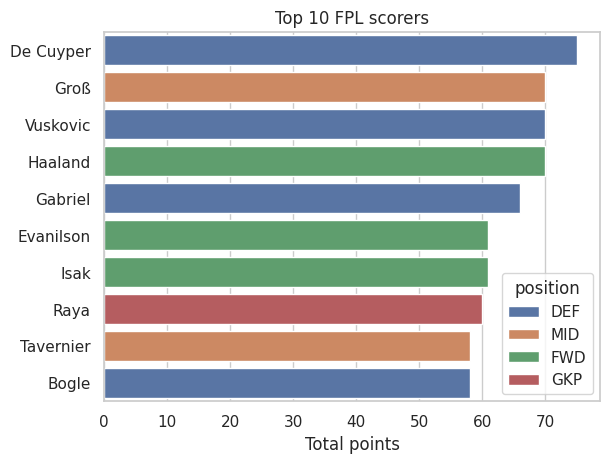

In [9]:
top10 = df.nlargest(10, "total_points")

sns.barplot(data=top10, x="total_points", y="web_name", hue="position", dodge=False)
plt.title("Top 10 FPL scorers")
plt.xlabel("Total points")
plt.ylabel("")
plt.show()

**Do expensive players score more?**

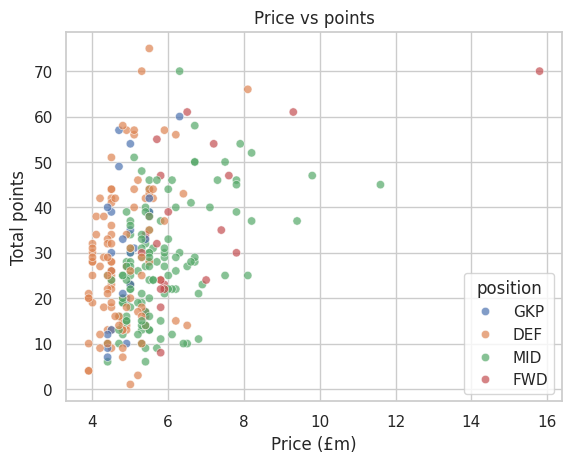

In [10]:
sns.scatterplot(data=df, x="price", y="total_points", hue="position", alpha=0.7)
plt.title("Price vs points")
plt.xlabel("Price (£m)")
plt.ylabel("Total points")
plt.show()

Mostly yes, but look at the spread. Plenty of cheap players outscore expensive ones. That's where value lives.

**Expected goals vs real goals**

Expected goals (xG) measures the quality of a player's chances. A player above the line is finishing better than expected. A player below it is missing chances, or getting unlucky.

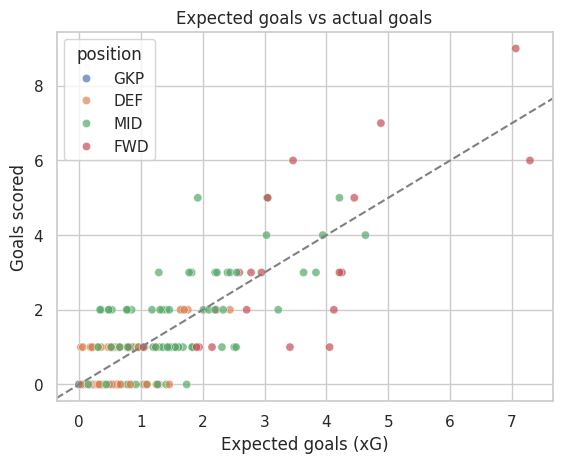

In [11]:
sns.scatterplot(data=df, x="expected_goals", y="goals_scored", hue="position", alpha=0.7)
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title("Expected goals vs actual goals")
plt.xlabel("Expected goals (xG)")
plt.ylabel("Goals scored")
plt.show()

**Which positions score the most?**

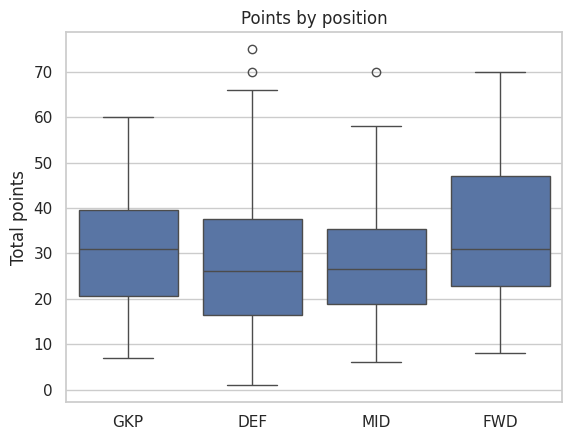

In [12]:
sns.boxplot(data=df, x="position", y="total_points", order=["GKP", "DEF", "MID", "FWD"])
plt.title("Points by position")
plt.xlabel("")
plt.ylabel("Total points")
plt.show()

## 6. Build a model

We want the model to learn: *given how a player has played, how many points should he have?*

So the inputs (**features**) are things that describe performance: minutes, chances created, chances taken, defending. We deliberately leave out actual goals and assists, because those are the "luck" part we want to measure.

The thing we predict (the **target**) is total points.

In [24]:
features = [
    "minutes", "starts", "price",
    "expected_goals", "expected_assists", "expected_goals_conceded", "clean_sheets",
    "defensive_contribution",
]

X = pd.get_dummies(df[features + ["position"]], columns=["position"], dtype=int)
y = df["total_points"]

X.head()

,minutes,starts,price,expected_goals,expected_assists,expected_goals_conceded,clean_sheets,defensive_contribution,position_DEF,position_FWD,position_GKP,position_MID
0,900,10,6.3,0.00,0.01,7.59,7,0,0,0,1,0
1,900,10,8.1,1.47,0.25,7.59,7,91,1,0,0,0
2,767,9,5.9,1.22,1.01,6.93,6,42,1,0,0,0
3,532,7,5.4,0.18,0.83,2.84,4,28,1,0,0,0
4,596,7,9.4,3.63,1.20,5.10,4,46,0,0,0,1


We split the data. The model learns from 80% of players (the **training set**) and we test it on the 20% it has never seen (the **test set**). Like studying past questions, then sitting a real exam.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

len(X_train), len(X_test)

(228, 58)

We try two models:

- **Linear regression**: draws the best straight-line relationship between features and points.
- **Random forest**: hundreds of small decision trees that vote. Can capture more complex patterns.

In [15]:
linear = LinearRegression().fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)

## 7. Evaluate the model

Two scores:

- **MAE** (mean absolute error): on average, how many points is the prediction off by? Lower is better.
- **R²**: how much of the difference between players the model explains. 1 is perfect, 0 is useless.

We also compare to a lazy **baseline**: guess the average for everyone. A model that can't beat that is worthless.

In [16]:
baseline = [y_train.mean()] * len(y_test)

results = pd.DataFrame({
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, linear.predict(X_test)),
        mean_absolute_error(y_test, forest.predict(X_test)),
    ],
    "R²": [
        r2_score(y_test, baseline),
        r2_score(y_test, linear.predict(X_test)),
        r2_score(y_test, forest.predict(X_test)),
    ],
}, index=["Guess the average", "Linear regression", "Random forest"]).round(2)

results

,MAE,R²
Guess the average,9.85,-0.00
Linear regression,6.18,0.65
Random forest,6.75,0.57


Pick the model with the lower MAE. Let's see how its predictions compare to reality. Points on the line are perfect predictions.

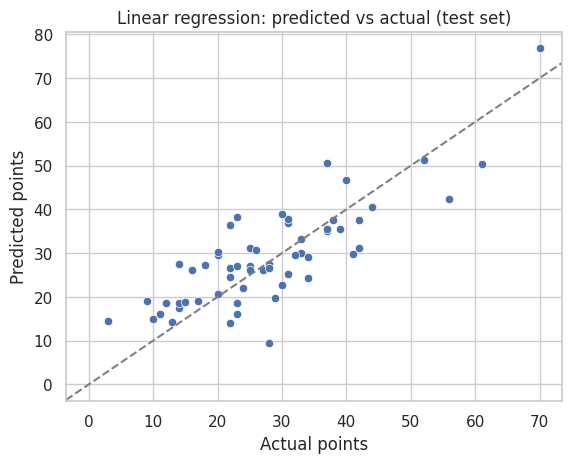

In [17]:
best_name = results["MAE"].iloc[1:].idxmin()
best_model = {"Linear regression": linear, "Random forest": forest}[best_name]

sns.scatterplot(x=y_test, y=best_model.predict(X_test))
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title(f"{best_name}: predicted vs actual (test set)")
plt.xlabel("Actual points")
plt.ylabel("Predicted points")
plt.show()

**What does the random forest think matters most?**

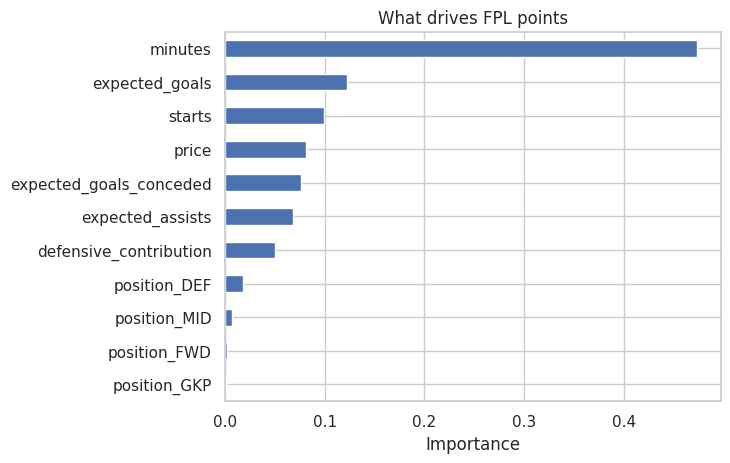

In [18]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh")
plt.title("What drives FPL points")
plt.xlabel("Importance")
plt.show()

## 8. Use the model

Now we answer the question. Every player gets an **expected points** score. To keep it fair, each player's prediction comes from a model that never saw him during training (`cross_val_predict` handles this).

- `luck` below zero: fewer points than his performances deserve. **Buy candidate.**
- `luck` above zero: more points than he deserves. Could cool off.

In [19]:
df["expected_points"] = cross_val_predict(best_model, X, y, cv=5).round(1)
df["luck"] = (df["total_points"] - df["expected_points"]).round(1)

show = ["web_name", "team", "position", "price", "total_points", "expected_points", "luck", "selected_by_percent"]

**Unluckiest players: due some points**

In [20]:
df.nsmallest(10, "luck")[show]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent
139,Gonzalo,Fulham,FWD,5.8,24,46.2,-22.2,3.3
57,Thiago,Brentford,FWD,7.8,30,49.0,-19.0,7.1
247,Sels,Nott'm Forest,GKP,5.0,23,41.0,-18.0,1.3
34,Rayan,Bournemouth,MID,6.3,30,47.9,-17.9,2.5
246,Muñoz,Nott'm Forest,DEF,5.2,17,34.2,-17.2,4.1
255,McAtee,Nott'm Forest,MID,5.5,27,43.5,-16.5,0.1
218,Maguire,Man Utd,DEF,4.6,16,32.4,-16.4,4.7
219,Martinez,Man Utd,DEF,4.8,9,25.0,-16.0,0.9
240,Wissa,Newcastle,FWD,5.9,22,37.5,-15.5,7.8
33,Smith,Bournemouth,DEF,4.5,23,37.9,-14.9,0.2


**Luckiest players: might cool off**

In [21]:
df.nlargest(10, "luck")[show]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent
62,De Cuyper,Brighton,DEF,5.5,75,42.7,32.3,49.3
69,Vuskovic,Brighton,DEF,5.3,70,41.7,28.3,10.9
65,Groß,Brighton,MID,6.3,70,46.8,23.2,49.0
11,Konsa,Arsenal,DEF,4.9,57,35.8,21.2,25.5
59,Verbruggen,Brighton,GKP,4.7,57,35.9,21.1,24.2
24,Alysson,Aston Villa,MID,4.9,28,9.3,18.7,0.5
120,Tarkowski,Everton,DEF,6.2,56,37.3,18.7,19.0
85,João Pedro,Chelsea,FWD,7.6,47,28.5,18.5,29.5
184,Trafford,Leeds,GKP,5.0,54,36.9,17.1,6.7
210,Cherki,Man City,MID,7.9,54,36.9,17.1,33.7


**Best value: expected points per £1m, available players only**

In [22]:
df["value"] = (df["expected_points"] / df["price"]).round(1)

(df[df["status"] == "a"]
   .sort_values("value", ascending=False)
   .groupby("position")
   .head(3)
   .sort_values(["position", "value"], ascending=[True, False])
   [show + ["value"]])

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent,value
258,Van Hecke,Spurs,DEF,5.1,57,48.6,8.4,17.2,9.5
174,Bogle,Leeds,DEF,4.8,58,44.1,13.9,11.3,9.2
176,Justin,Leeds,DEF,4.5,51,40.7,10.3,2.5,9.0
129,Barry,Everton,FWD,5.7,55,62.4,-7.4,11.4,10.9
41,Evanilson,Bournemouth,FWD,6.5,61,51.9,9.1,25.5,8.0
139,Gonzalo,Fulham,FWD,5.8,24,46.2,-22.2,3.3,8.0
262,Kinsky,Spurs,GKP,4.4,40,38.9,1.1,15.8,8.8
30,Petrović,Bournemouth,GKP,4.5,30,37.8,-7.8,3.2,8.4
247,Sels,Nott'm Forest,GKP,5.0,23,41.0,-18.0,1.3,8.2
281,E.Le Fée,Sunderland,MID,5.7,46,49.0,-3.0,3.0,8.6


In [25]:
goalkeepers = df[
    (df["position"] == "GKP") &
    (df["price"] < 5) &
    (df["status"] == "a")
]

goalkeepers.sort_values(
    "value", ascending=False
)[show + ["value"]]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent,value
189,Kinsky,Spurs,GKP,4.4,40,38.9,1.1,15.8,8.8
20,Petrović,Bournemouth,GKP,4.5,30,37.8,-7.8,3.2,8.4
89,Leno,Fulham,GKP,4.5,39,35.0,4.0,4.3,7.8
39,Verbruggen,Brighton,GKP,4.7,57,35.9,21.1,24.2,7.6
61,Rushworth,Coventry City,GKP,4.5,26,33.7,-7.7,0.8,7.5
107,Tzolakis,Hull City,GKP,4.7,49,34.6,14.4,13.3,7.4
197,Roefs,Sunderland,GKP,4.8,33,33.1,-0.1,1.9,6.9
157,Lammens,Man Utd,GKP,4.8,21,31.5,-10.5,7.0,6.6
50,Martinez,Chelsea,GKP,4.9,20,23.1,-3.1,3.0,4.7
112,Walton,Ipswich Town,GKP,4.4,12,18.3,-6.3,0.5,4.2


## 9. Share the work

A finding that stays on your laptop helps nobody. Data scientists share:

- **A short summary** for non-technical people: "These 5 players are underpriced, here's why."
- **The code** on GitHub, so anyone can check it and rerun it.

**Save this notebook to GitHub from Colab:** `File` → `Save a copy in GitHub` → pick your repository → add a commit message → OK.

### Things to remember

- The data is **live**. Run this next week and the answers change.
- Expected points is not a promise. It says who *deserves* more, not who will get it.
- The model only knows what we gave it. No injuries, no fixtures, no form. Those are ideas for improving it.

### Try it yourself

1. Change the minutes filter from 270 to 450. Do the results change?
2. Add `"clean_sheets"` to the features. Does the MAE get better?
3. Find the best value goalkeeper under £5m.